# Computation of Effective area

## Summary
- Load selected gamma rays and all gamma rays from MC
- Bins : 20 in Energy from 1 to 100 GeV, 10 in theta from 0 to 60° (Duan)
- Raffiner les bins par endroit? 

In [1]:
import ROOT, glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

## Load MC data

In [2]:
dirDir= "/home/users/l/lebrun/"
dataDir = "/dpnc/beegfs/dampe/tryf/MC_Skimmed/MC_gamma/"
figPath = dirDir + "figures/"
resultPath = dirDir + "results/"
dataPath = dirDir + "data/"
filename1 = dataDir + "DmlNtup_gamma_part*_TQ_FullSel.root"
filename2 = dataDir + "DmlNtup_gamma_100GeV_1TeV_part*_TQ_FullSel.root"
filename3 = dataDir + "DmlNtup_gamma_1TeV_10TeV_part*_MPhotonSelProj_TQ_FullSel.root"

filenames_LET = [filename1, filename2]
filenames_HET = [filename1, filename2, filename3]

# Find all matching ROOT files : from 1 GeV to 100 GeV
files = list()
for filename in filenames_HET:
    files += sorted(glob.glob(filename))

# Pass the list of files to RDataFrame

rdf = ROOT.RDataFrame("DmlNtup", files)

# Apply cut on HET
rdf = rdf.Filter("theta_True < 60")

# Extract only desired columns
df = rdf.AsNumpy(["tt_ekin", "tt_bgoTotalEcorr_GeV", "theta_True", "tt_isHET", "tt_isHET"])
df = pd.DataFrame(df)

## Necessary transformations

In [3]:
df['Etrue'] = df['tt_ekin'] * 1e-3
df['Erec'] = df['tt_bgoTotalEcorr_GeV']
#Print number of events
print("Number of events in the DataFrame: ", len(df))

df['theta_True_deg']= df['theta_True']
df['theta_True'] = np.deg2rad(df['theta_True'])
df['cosTheta'] = np.cos(df['theta_True'])

Number of events in the DataFrame:  29846752


## TODO : load filtered data

In [4]:
# Load filtered data here
exponent = -2.5
dfHET = pd.read_csv(dataPath + f"MC_het_exp{exponent:.1f}_filtered_energy.csv")
dfHET = dfHET[dfHET['tt_isHET'] == 1]

dfHET['Etrue'] = dfHET['tt_ekin'] * 1e-3
dfHET = dfHET[dfHET['Etrue'] <= 1e4]

dfHET['theta_True_deg']= dfHET['theta_True']
dfHET['theta_True'] = np.deg2rad(dfHET['theta_True'])
dfHET['cosTheta'] = np.cos(dfHET['theta_True'])

## Create bins

In [ ]:
Emin = 1
Emax_HET = 1e4
n_E_bins_HET = 40

cos_theta_min = 0.5
cos_theta_max = 1
n_theta_bins = 10

E_bins_edge_HET = np.logspace(np.log10(Emin), np.log10(Emax_HET), n_E_bins_HET + 1)
E_bins_center_HET = np.sqrt(E_bins_edge_HET[:-1] * E_bins_edge_HET[1:])

theta_bins_edge = np.linspace(cos_theta_min, cos_theta_max, n_theta_bins + 1)
theta_bins_center = (theta_bins_edge[:-1] + theta_bins_edge[1:])/2

### Bin the MC data

In [6]:
# Assign bin indices
df['E_bin_HET'] = pd.cut(df['Etrue'], bins=E_bins_edge_HET, labels=False, include_lowest=True)
df['E_bin_HET'] = pd.cut(df['Etrue'], bins=E_bins_edge_HET, labels=False, include_lowest=True)
df['cos_theta_bin'] = pd.cut(df['cosTheta'], bins=theta_bins_edge, labels=False, include_lowest=True)

# Drop rows that fall outside the bins (e.g., NaN bin index)
df = df.dropna(subset=['E_bin_HET', 'E_bin_HET' , 'cos_theta_bin']).copy() # Copy to avoid SettingWithCopyWarning

# Make sure bin indices are integers
df['E_bin_HET'] = df['E_bin_HET'].astype(int)
df['E_bin_HET'] = df['E_bin_HET'].astype(int)
df['cos_theta_bin'] = df['cos_theta_bin'].astype(int)

### Bin the HET data

In [7]:
dfHET['E_bin_HET'] = pd.cut(dfHET['Etrue'], bins=E_bins_edge_HET, labels=False, include_lowest=True)
dfHET['cos_theta_bin'] = pd.cut(dfHET['cosTheta'], bins=theta_bins_edge, labels=False, include_lowest=True)
dfHET = dfHET.dropna(subset=['E_bin_HET', 'cos_theta_bin']).copy() # Copy to avoid SettingWithCopyWarning
dfHET['E_bin_HET'] = dfHET['E_bin_HET'].astype(int)
dfHET['cos_theta_bin'] = dfHET['cos_theta_bin'].astype(int)

In [8]:
print(dfHET)

              tt_ekin  tt_bgoTotalEcorr_GeV  theta_True  tt_isLET  tt_isHET  \
0        4.144791e+03              3.910873    0.669844       1.0       1.0   
1        8.178751e+04             83.132685    0.222307       1.0       1.0   
2        4.193700e+03              4.155001    0.698137       1.0       1.0   
3        1.940030e+04             18.746079    0.411329       1.0       1.0   
4        1.133980e+04             11.181992    0.402023       1.0       1.0   
...               ...                   ...         ...       ...       ...   
2500067  9.263475e+06           9228.972444    0.495240       1.0       1.0   
2500068  1.467389e+06           1464.339116    0.472372       1.0       1.0   
2500069  4.061424e+06           4037.328153    0.441122       1.0       1.0   
2500070  1.230132e+06           1232.419032    0.315941       1.0       1.0   
2500071  1.109695e+06           1111.399501    0.259302       1.0       1.0   

               weight        Etrue  theta_True_deg 

## Bin df_results

In [9]:
# Group original events (denominator)
total_counts = (
    df.groupby(['E_bin_HET', 'cos_theta_bin'])
    .size()
    .rename('total')
)

# Group accepted events (numerator)
accepted_counts = (
    dfHET.groupby(['E_bin_HET', 'cos_theta_bin'])
    .size()
    .rename('accepted')
)

print(total_counts)
print(accepted_counts)

# Join and compute acceptance and effarea
r = 1.38*1e2 # cm
df_results_geom = 37.59 * 1e4 # cm^2 sr
eff_area_geom = (np.pi)*(r**2)
df_results = pd.concat([accepted_counts, total_counts], axis=1).fillna(0)
print(df_results.head())
df_results['acceptance'] = df_results['accepted'] * df_results_geom / df_results['total']
df_results['effArea'] = df_results['accepted'] * eff_area_geom / df_results['total']
# Optional: reset index if you want a flat DataFrame
df_results = df_results.reset_index()
df_results = df_results.sort_values(['E_bin_HET', 'cos_theta_bin'])
print(df_results)
# If you want to save:
df_results.to_csv(resultPath + "df_results_HET.csv", index=False)


E_bin_HET  cos_theta_bin
0          0                28950
           1                35023
           2                40542
           3                46132
           4                52506
                            ...  
39         5                 3147
           6                 3216
           7                 3470
           8                 3242
           9                 3476
Name: total, Length: 400, dtype: int64
E_bin_HET  cos_theta_bin
0          8                  1
1          2                  1
           3                  4
           4                  2
           5                  3
                           ... 
39         5                212
           6                293
           7                388
           8                406
           9                460
Name: accepted, Length: 388, dtype: int64
                         accepted   total
E_bin_HET cos_theta_bin                  
0         8                   1.0   75856
1         2      

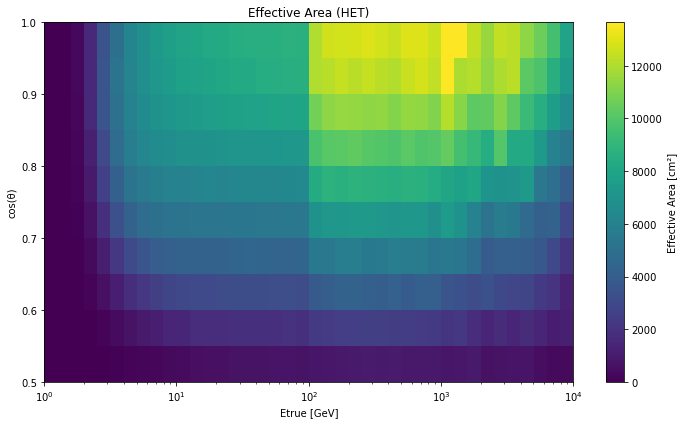

In [10]:
# Create 2D array of df_results values: shape (n_theta_bins, n_E_bins)
df_results_grid = df_results.pivot(index='cos_theta_bin', columns='E_bin_HET', values='effArea').values


fig, ax = plt.subplots(figsize=(10, 6))
mesh = ax.pcolormesh(
    E_bins_edge_HET, theta_bins_edge, df_results_grid,
    shading='auto', cmap='viridis'
)

# Log scale for E axis if needed
ax.set_xscale('log')

# Labels and title
ax.set_xlabel("Etrue [GeV]")
ax.set_ylabel("cos(θ)")
ax.set_title("Effective Area (HET)")
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("Effective Area [cm²]")

plt.tight_layout()
plt.show()

## Explo : which MC photon is which trigger?

In [11]:
# Plot Energy histogram of df which belong to neither HET nor HET
def create_log_bins(min_val, max_val, n_bins):
    """Create logarithmically spaced bin edges"""
    return np.logspace(np.log10(min_val), np.log10(max_val), n_bins + 1)

rdf = rdf.Define("Etrue", "tt_ekin * 1e-3")  # Convert to GeV

rdf_none = rdf.Filter("tt_isLET == 0").Filter("tt_isHET == 0")
rdf_LET = rdf.Filter("tt_isLET == 1")
rdf_LETnonHET = rdf.Filter("tt_isLET == 1").Filter("tt_isHET == 0")
rdf_HETnonLET = rdf.Filter("tt_isLET == 0").Filter("tt_isHET == 1")
rdf_HET = rdf.Filter("tt_isHET == 1")


In [12]:

n_bins = 30
min_val = 1
max_val = 100

log_bins = create_log_bins(min_val, max_val, n_bins)
log_bins_root = ROOT.std.vector('double')(log_bins)

h_none = rdf_none.Histo1D(("hNone", "; Energy [GeV]; Counts",n_bins, log_bins_root.data()), 'Etrue')
h_LET = rdf_HET.Histo1D(("hLET", "; Energy [GeV]; Counts", n_bins, log_bins_root.data()), 'Etrue')
h_LETnonHET = rdf_LETnonHET.Histo1D(("hLETnonHET", "; Energy [GeV]; Counts", n_bins, log_bins_root.data()), 'Etrue')
h_HETnonLET = rdf_HETnonLET.Histo1D(("hHETnonLET", "; Energy [GeV]; Counts", n_bins, log_bins_root.data()), 'Etrue')
h_HET = rdf_HET.Histo1D(("hHET", "; Energy [GeV]; Counts", n_bins, log_bins_root.data()), 'Etrue')

In [13]:

# Style
h_none.SetLineColor(ROOT.kBlack)
h_LET.SetLineColor(ROOT.kBlue)
h_LETnonHET.SetLineColor(ROOT.kCyan+1)
h_HETnonLET.SetLineColor(ROOT.kRed)
h_HET.SetLineColor(ROOT.kMagenta)

h_none.SetMarkerStyle(1)
h_LET.SetMarkerStyle(1)
h_LETnonHET.SetMarkerStyle(1)
h_HETnonLET.SetMarkerStyle(1)
h_HET.SetMarkerStyle(1)


h_none.GetXaxis().SetLabelOffset(0.005)
h_none.GetXaxis().SetTitleOffset(1.3)
h_LET.GetXaxis().SetLabelOffset(0.005)
h_LET.GetXaxis().SetTitleOffset(1.3)
h_LETnonHET.GetXaxis().SetLabelOffset(0.005)
h_LETnonHET.GetXaxis().SetTitleOffset(1.3)
h_HETnonLET.GetXaxis().SetLabelOffset(0.005)
h_HETnonLET.GetXaxis().SetTitleOffset(1.3)
h_HET.GetXaxis().SetLabelOffset(0.005)
h_HET.GetXaxis().SetTitleOffset(1.3)

# Draw
ROOT.gStyle.SetOptStat(0)
c = ROOT.TCanvas()

h_none.SetStats(0)

h_none.Draw("HIST")
h_LET.Draw("HIST SAME")
h_LETnonHET.Draw("HIST SAME")
h_HETnonLET.Draw("HIST SAME")
h_HET.Draw("HIST SAME")


legend = ROOT.TLegend(0.6, 0.6, 0.89, 0.89)  # x1, y1, x2, y2

legend.AddEntry(h_none.GetPtr(), "None", "l")
legend.AddEntry(h_LET.GetPtr(), "LET", "l")
legend.AddEntry(h_LETnonHET.GetPtr(), "LET only", "l")
legend.AddEntry(h_HETnonLET.GetPtr(), "HET only", "l")
legend.AddEntry(h_HET.GetPtr(), "HET", "l")

legend.SetBorderSize(0)
legend.SetFillStyle(0)
legend.Draw("SAME")

c.SetLogy()
c.SetLogx()
c.Update()
c.SaveAs(figPath + "scaling/" + "Spectrum_triggers_1_100.pdf")
c.Draw()

Info in <TCanvas::Print>: pdf file /home/users/l/lebrun/figures/scaling/Spectrum_triggers_1_100.pdf has been created


In [14]:

n_bins = 60
min_val = 1
max_val = 10000

log_bins = create_log_bins(min_val, max_val, n_bins)
log_bins_root = ROOT.std.vector('double')(log_bins)

h_none = rdf_none.Histo1D(("hNone", "; Energy [GeV]; Counts",n_bins, log_bins_root.data()), 'Etrue')
h_LET = rdf_HET.Histo1D(("hLET", "; Energy [GeV]; Counts", n_bins, log_bins_root.data()), 'Etrue')
h_LETnonHET = rdf_LETnonHET.Histo1D(("hLETnonHET", "; Energy [GeV]; Counts", n_bins, log_bins_root.data()), 'Etrue')
h_HETnonLET = rdf_HETnonLET.Histo1D(("hHETnonLET", "; Energy [GeV]; Counts", n_bins, log_bins_root.data()), 'Etrue')
h_HET = rdf_HET.Histo1D(("hHET", "; Energy [GeV]; Counts", n_bins, log_bins_root.data()), 'Etrue')


# Style
h_none.SetLineColor(ROOT.kBlack)
h_LET.SetLineColor(ROOT.kBlue)
h_LETnonHET.SetLineColor(ROOT.kCyan+1)
h_HETnonLET.SetLineColor(ROOT.kRed)
h_HET.SetLineColor(ROOT.kMagenta)

h_none.SetMarkerStyle(1)
h_LET.SetMarkerStyle(1)
h_LETnonHET.SetMarkerStyle(1)
h_HETnonLET.SetMarkerStyle(1)
h_HET.SetMarkerStyle(1)

h_none.GetXaxis().SetLabelOffset(0.005)
h_none.GetXaxis().SetTitleOffset(1.3)
h_LET.GetXaxis().SetLabelOffset(0.005)
h_LET.GetXaxis().SetTitleOffset(1.3)
h_LETnonHET.GetXaxis().SetLabelOffset(0.005)
h_LETnonHET.GetXaxis().SetTitleOffset(1.3)
h_HETnonLET.GetXaxis().SetLabelOffset(0.005)
h_HETnonLET.GetXaxis().SetTitleOffset(1.3)
h_HET.GetXaxis().SetLabelOffset(0.005)
h_HET.GetXaxis().SetTitleOffset(1.3)

# Draw
ROOT.gStyle.SetOptStat(0)
c1 = ROOT.TCanvas()

h_none.SetStats(0)

h_none.Draw("HIST")
h_LET.Draw("HIST SAME")
h_LETnonHET.Draw("HIST SAME")
h_HETnonLET.Draw("HIST SAME")
h_HET.Draw("HIST SAME")


legend2 = ROOT.TLegend(0.6, 0.6, 0.89, 0.89)  # x1, y1, x2, y2

legend2.AddEntry(h_none.GetPtr(), "None", "l")
legend2.AddEntry(h_LET.GetPtr(), "LET", "l")
legend2.AddEntry(h_LETnonHET.GetPtr(), "LET only", "l")
legend2.AddEntry(h_HETnonLET.GetPtr(), "HET only", "l")
legend2.AddEntry(h_HET.GetPtr(), "HET", "l")

legend2.SetBorderSize(0)
legend2.SetFillStyle(0)
legend2.Draw("SAME")

c1.SetLogy()
c1.SetLogx()
c1.Update()
c1.SaveAs(figPath + "scaling/" + "Spectrum_triggers_1_1e5.pdf")
c1.Draw()

Info in <TCanvas::Print>: pdf file /home/users/l/lebrun/figures/scaling/Spectrum_triggers_1_1e5.pdf has been created
